<a href="https://colab.research.google.com/github/ReziaBanu/Taxi_Data_Analysis/blob/main/Taxi_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [ ]:
df = sns.load_dataset("taxis")
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [ ]:
print(type(df))
print(df.shape)
print("\n")
print(df.columns.tolist())
print("\n")
print("\nDataset Information:")
df.info()
print("\n")
print("\nStatistical Summary:")
df.describe()

<class 'pandas.core.frame.DataFrame'>
(6433, 14)


['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_z

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223616,2019-03-16 08:45:49.491217408,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


In [ ]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Identify columns containing missing values
missing_columns = df.columns[df.isnull().any()]

print("\nColumns with Missing Data:")
print(missing_columns)

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with Missing Data:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')

Total Missing Values: 186


In [ ]:
import pandas as pd
df_clean = df.copy()
df_clean["pickup"] = pd.to_datetime(df_clean["pickup"])
df.dropna(subset=['pickup', 'fare', 'distance'], inplace=True)

df_clean["dropoff"] = pd.to_datetime(df_clean["dropoff"])
df_clean.dropna(subset=['dropoff', 'fare', 'distance'], inplace=True)
print("\n")
print(df_clean[["pickup", "dropoff"]].head())

print("\n")
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns




               pickup             dropoff
0 2019-03-23 20:21:09 2019-03-23 20:27:24
1 2019-03-04 16:11:55 2019-03-04 16:19:00
2 2019-03-27 17:53:01 2019-03-27 18:00:25
3 2019-03-10 01:23:59 2019-03-10 01:49:51
4 2019-03-30 13:27:42 2019-03-30 13:37:14




In [ ]:
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


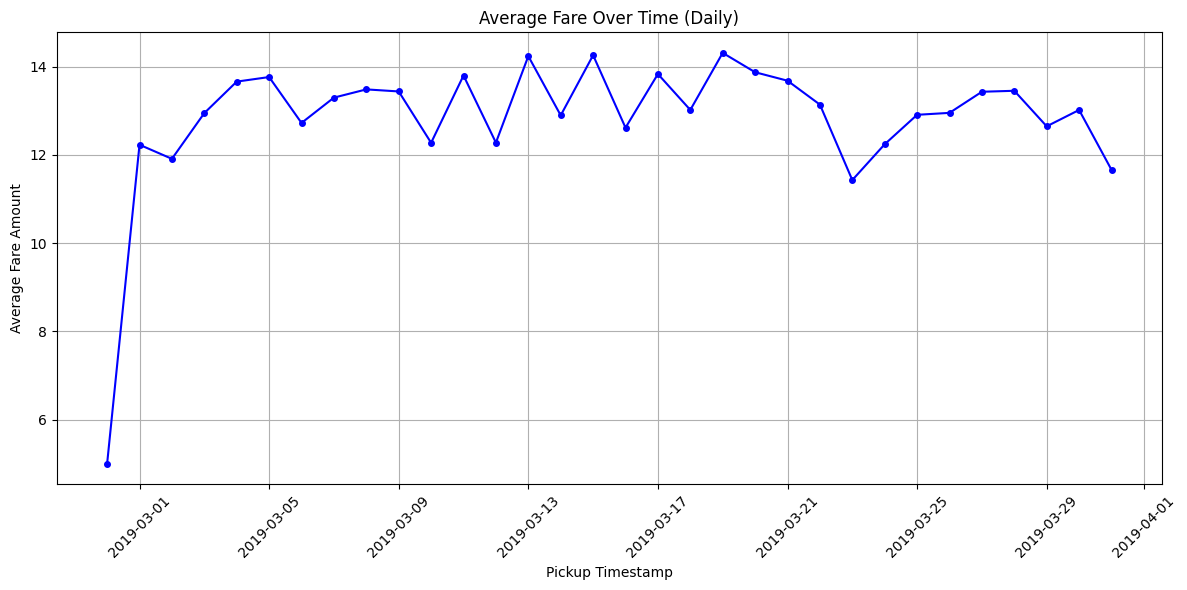

In [ ]:
import matplotlib.pyplot as plt

df['pickup'] = pd.to_datetime(df['pickup'])
df_sorted = df.sort_values('pickup')

# 2. Optional: Resample/aggregate to daily average to reduce clutter
df_daily = df_sorted.set_index('pickup').resample('D')['fare'].mean().reset_index()

# 3. Plot the cleaned/aggregated data
plt.figure(figsize=(12, 6))
plt.plot(df_daily['pickup'], df_daily['fare'], color='blue', linewidth=1.5, marker='o', markersize=4)

plt.title('Average Fare Over Time (Daily)')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Average Fare Amount')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Generating Bar Chart: Total Fare by Pickup Borough...


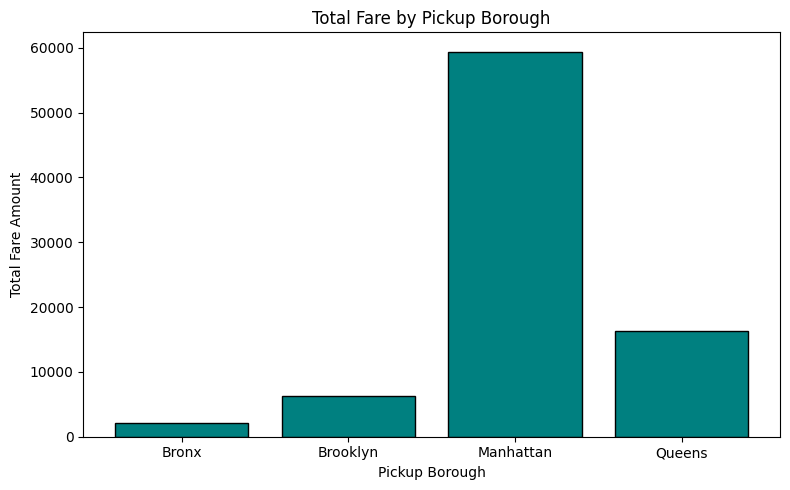

In [ ]:
print("Generating Bar Chart: Total Fare by Pickup Borough...")
borough_fare = df.groupby('pickup_borough')['fare'].sum().reset_index()

plt.figure(figsize=(8, 5))
plt.bar(borough_fare['pickup_borough'], borough_fare['fare'], color='teal', edgecolor='black')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Generating Pie Chart: Trip Distribution by Payment Method...


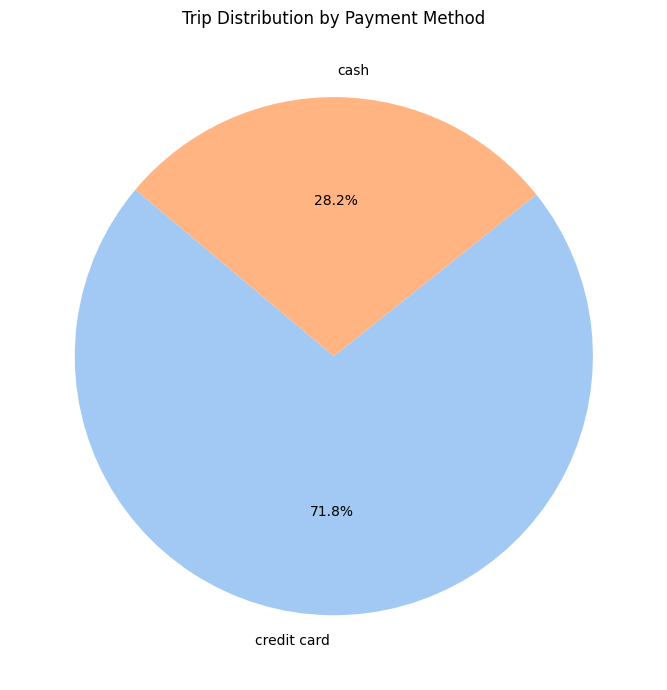

In [ ]:
print("Generating Pie Chart: Trip Distribution by Payment Method...")
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Trip Distribution by Payment Method')
plt.tight_layout()
plt.show()

Generating Histogram: Distance Distribution...


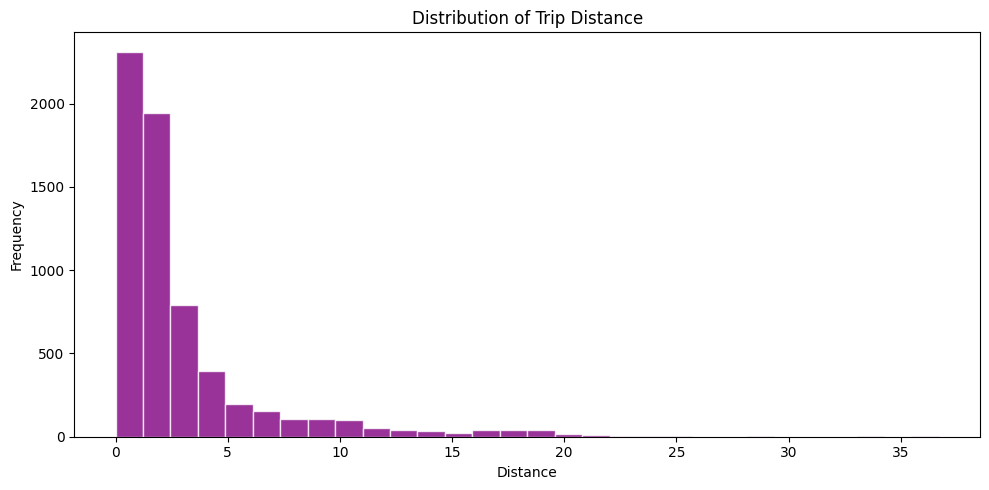

In [ ]:
print("Generating Histogram: Distance Distribution...")
plt.figure(figsize=(10, 5))
plt.hist(df['distance'], bins=30, color='purple', edgecolor='white', alpha=0.8)
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Generating Box Plot: Tip Amounts by Pickup Borough...


<Figure size 1000x600 with 0 Axes>

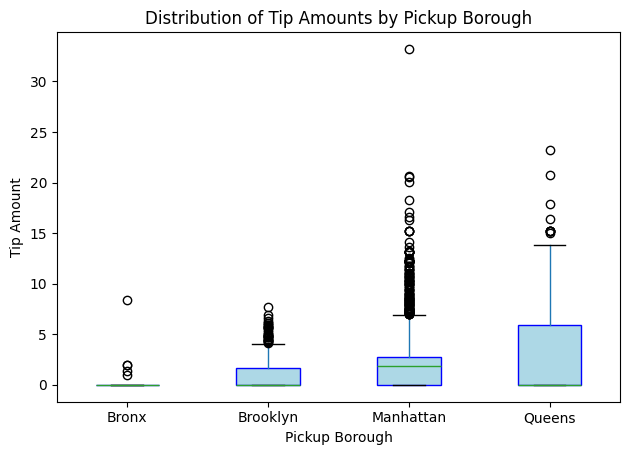

In [ ]:
print("Generating Box Plot: Tip Amounts by Pickup Borough...")
plt.figure(figsize=(10, 6))
df.boxplot(column='tip', by='pickup_borough', grid=False, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='blue'))
plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('') # Suppress automatic pandas multi-index title
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.tight_layout()
plt.show()

Generating Count Plot: Trips per Pickup Borough...


/tmp/ipykernel_644/1010358646.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='pickup_borough', palette='Set2')


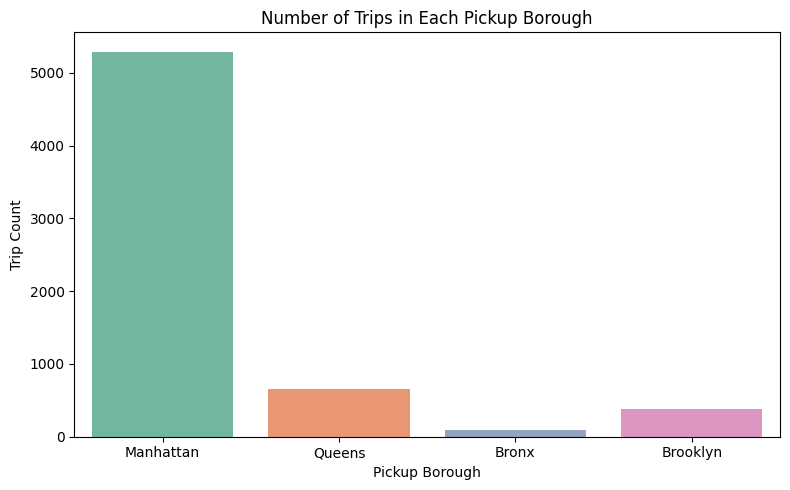

In [ ]:
print("Generating Count Plot: Trips per Pickup Borough...")
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='pickup_borough', palette='Set2')
plt.title('Number of Trips in Each Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Trip Count')
plt.tight_layout()
plt.show()

Generating Scatter Plot: Distance vs Fare...


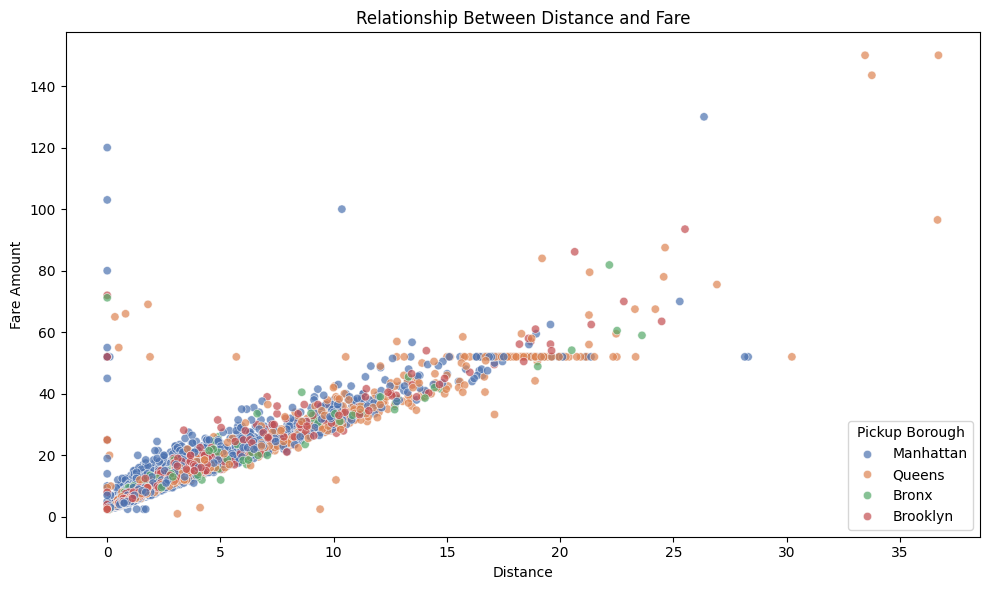

In [ ]:
print("Generating Scatter Plot: Distance vs Fare...")
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough', alpha=0.7, palette='deep')
plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare Amount')
plt.legend(title='Pickup Borough')
plt.tight_layout()
plt.show()

Generating Heatmap: Correlation Matrix...


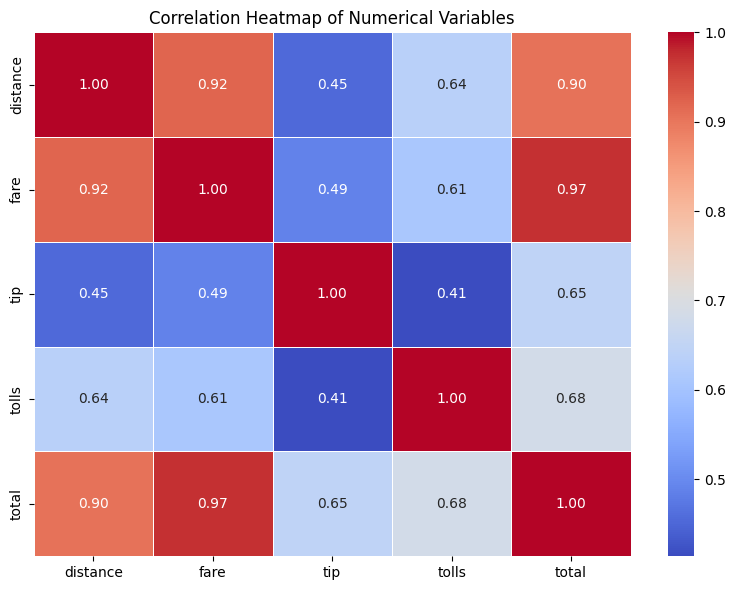

In [ ]:
print("Generating Heatmap: Correlation Matrix...")
num_vars = ['distance', 'fare', 'tip', 'tolls', 'total']
corr_matrix = df[num_vars].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

Generating Pair Plot (Note: This may take a few moments)...


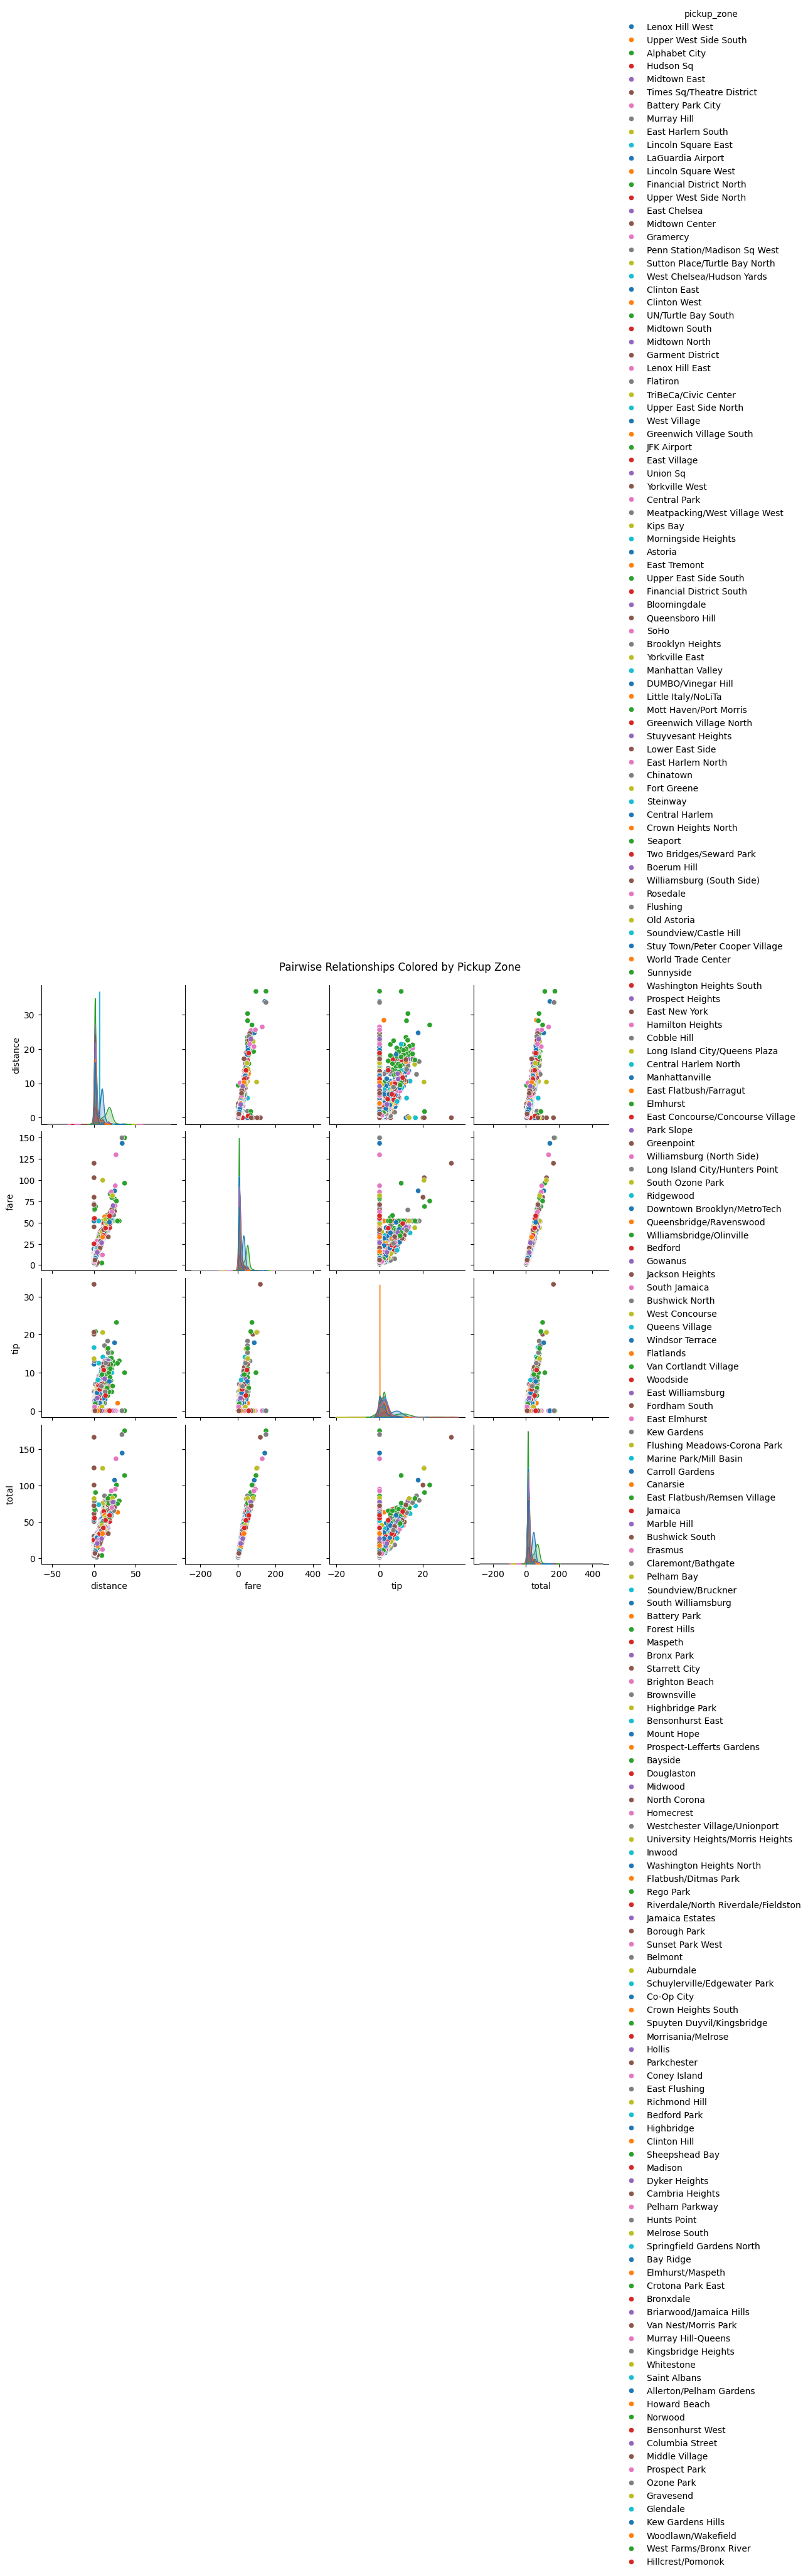

In [ ]:
print("Generating Pair Plot (Note: This may take a few moments)...")
# Using a subset or sample if dataset is large, or filtering top zones to keep visualization clear
sns.pairplot(df, vars=['distance', 'fare', 'tip', 'total'], hue='pickup_zone', palette='tab10', diag_kind='kde')
plt.suptitle('Pairwise Relationships Colored by Pickup Zone', y=1.02)
plt.show()

Generating Violin Plot: Fare Distribution by Payment Method...


/tmp/ipykernel_644/4242245408.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='payment', y='fare', palette='muted')


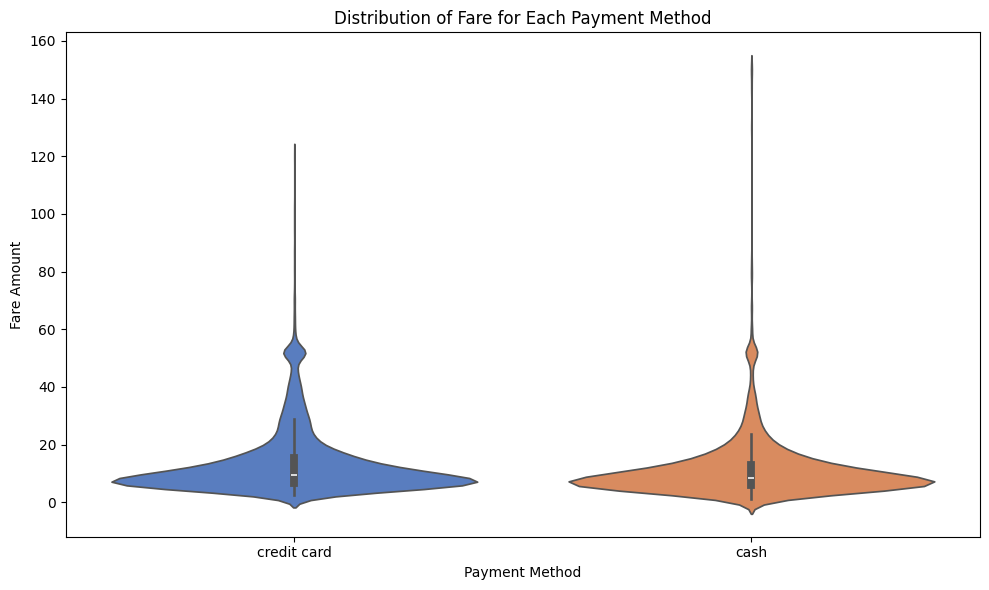

In [ ]:
print("Generating Violin Plot: Fare Distribution by Payment Method...")
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='payment', y='fare', palette='muted')
plt.title('Distribution of Fare for Each Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')
plt.tight_layout()
plt.show()